SECURESENSE - HISTOGRAM GRADIENT BOOSTING

Loading training data...
Loading testing data...

Training shape: (1785012, 70)
Testing shape : (446254, 70)

Number of features: 69

TRAINING HISTOGRAM GRADIENT BOOSTING

Training completed in 51.54 seconds

Generating predictions...

HISTOGRAM GRADIENT BOOSTING RESULTS

Accuracy  : 0.999256 (99.93%)
Precision : 0.997887 (99.79%)
Recall    : 0.997175 (99.72%)
F1 Score  : 0.997531 (99.75%)
ROC-AUC   : 0.999989 (100.00%)
PR-AUC    : 0.999954 (100.00%)
Train Time: 51.54 seconds

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      BENIGN     0.9995    0.9996    0.9996    379009
      ATTACK     0.9979    0.9972    0.9975     67245

    accuracy                         0.9993    446254
   macro avg     0.9987    0.9984    0.9985    446254
weighted avg     0.9993    0.9993    0.9993    446254


CONFUSION MATRIX
[[378867    142]
 [   190  67055]]


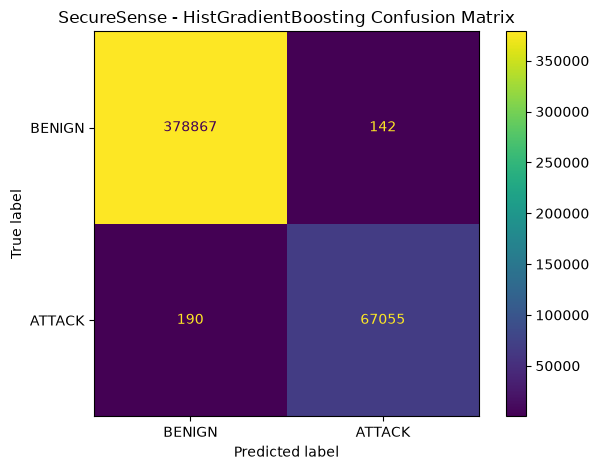

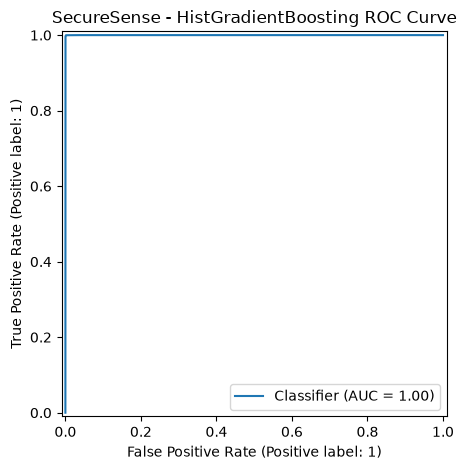

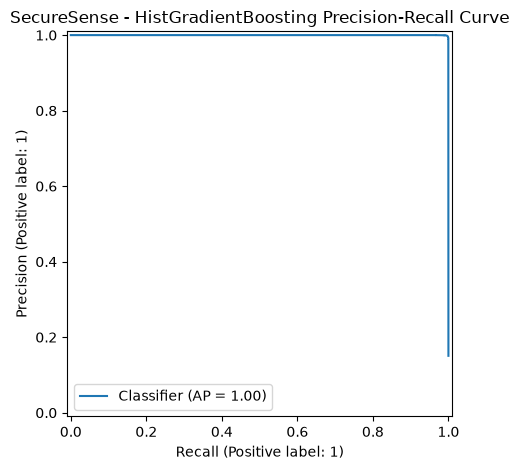


HISTOGRAM GRADIENT BOOSTING COMPLETED

Model saved to: ../models\hist_gradient_boosting.pkl
Metrics saved to: ../results\hist_gradient_boosting_metrics.csv

Final Metrics:
               Model  Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC  Training_Time_Seconds
HistGradientBoosting  0.999256   0.997887 0.997175 0.997531 0.999989 0.999954              51.542232

Next: ANN


In [1]:
# ============================================================
# SECURESENSE - HISTOGRAM GRADIENT BOOSTING
# ============================================================

import os
import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# ============================================================
# 1. PATHS
# ============================================================

TRAIN_PATH = "../data/splits/train.parquet"
TEST_PATH = "../data/splits/test.parquet"

MODEL_DIR = "../models"
RESULT_DIR = "../results"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# ============================================================
# 2. LOAD DATA
# ============================================================

print("=" * 80)
print("SECURESENSE - HISTOGRAM GRADIENT BOOSTING")
print("=" * 80)

print("\nLoading training data...")
train_df = pd.read_parquet(TRAIN_PATH)

print("Loading testing data...")
test_df = pd.read_parquet(TEST_PATH)

print(f"\nTraining shape: {train_df.shape}")
print(f"Testing shape : {test_df.shape}")

# ============================================================
# 3. FEATURES AND TARGET
# ============================================================

TARGET = "BinaryLabel"

X_train = train_df.drop(columns=[TARGET])
X_test = test_df.drop(columns=[TARGET])

y_train = train_df[TARGET].astype(int)
y_test = test_df[TARGET].astype(int)

print(f"\nNumber of features: {X_train.shape[1]}")

# ============================================================
# 4. MODEL
# ============================================================

print("\n" + "=" * 80)
print("TRAINING HISTOGRAM GRADIENT BOOSTING")
print("=" * 80)

model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.10,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42
)

start_time = time.time()

model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"\nTraining completed in {training_time:.2f} seconds")

# ============================================================
# 5. PREDICTIONS
# ============================================================

print("\nGenerating predictions...")

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# ============================================================
# 6. METRICS
# ============================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print("\n" + "=" * 80)
print("HISTOGRAM GRADIENT BOOSTING RESULTS")
print("=" * 80)

print(f"\nAccuracy  : {accuracy:.6f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.6f} ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.6f} ({recall * 100:.2f}%)")
print(f"F1 Score  : {f1:.6f} ({f1 * 100:.2f}%)")
print(f"ROC-AUC   : {roc_auc:.6f} ({roc_auc * 100:.2f}%)")
print(f"PR-AUC    : {pr_auc:.6f} ({pr_auc * 100:.2f}%)")
print(f"Train Time: {training_time:.2f} seconds")

# ============================================================
# 7. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "ATTACK"],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 8. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred)

print("\n" + "=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

disp.plot()
plt.title("SecureSense - HistGradientBoosting Confusion Matrix")
plt.tight_layout()
plt.show()

# ============================================================
# 9. ROC CURVE
# ============================================================

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("SecureSense - HistGradientBoosting ROC Curve")
plt.tight_layout()
plt.show()

# ============================================================
# 10. PRECISION-RECALL CURVE
# ============================================================

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title("SecureSense - HistGradientBoosting Precision-Recall Curve")
plt.tight_layout()
plt.show()

# ============================================================
# 11. SAVE MODEL
# ============================================================

model_path = os.path.join(
    MODEL_DIR,
    "hist_gradient_boosting.pkl"
)

joblib.dump(model, model_path)

# ============================================================
# 12. SAVE METRICS
# ============================================================

metrics = pd.DataFrame([{
    "Model": "HistGradientBoosting",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
    "Training_Time_Seconds": training_time
}])

metrics_path = os.path.join(
    RESULT_DIR,
    "hist_gradient_boosting_metrics.csv"
)

metrics.to_csv(metrics_path, index=False)

print("\n" + "=" * 80)
print("HISTOGRAM GRADIENT BOOSTING COMPLETED")
print("=" * 80)

print(f"\nModel saved to: {model_path}")
print(f"Metrics saved to: {metrics_path}")

print("\nFinal Metrics:")
print(metrics.to_string(index=False))

print("\nNext: ANN")

SECURESENSE - FINAL GROUP-AWARE HISTOGRAM GRADIENT BOOSTING

✓ Training file found
✓ Testing file found

Loading training data...
Loading testing data...

Training shape: (1555942, 72)
Testing shape : (675324, 72)

Number of features: 69

Source-file overlap: 0
✓ No source-file overlap

TRAINING HISTOGRAM GRADIENT BOOSTING

Training completed in 37.47 seconds

Generating predictions...

FINAL HISTOGRAM GRADIENT BOOSTING RESULTS

Accuracy  : 0.928962 (92.90%)
Precision : 0.988895 (98.89%)
Recall    : 0.632336 (63.23%)
F1 Score  : 0.771407 (77.14%)
ROC-AUC   : 0.948125 (94.81%)
PR-AUC    : 0.850233 (85.02%)
Train Time: 37.47 seconds

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      BENIGN     0.9207    0.9983    0.9579    547313
      ATTACK     0.9889    0.6323    0.7714    128011

    accuracy                         0.9290    675324
   macro avg     0.9548    0.8153    0.8647    675324
weighted avg     0.9336    0.9290    0.9226    675324


CONFUSION 

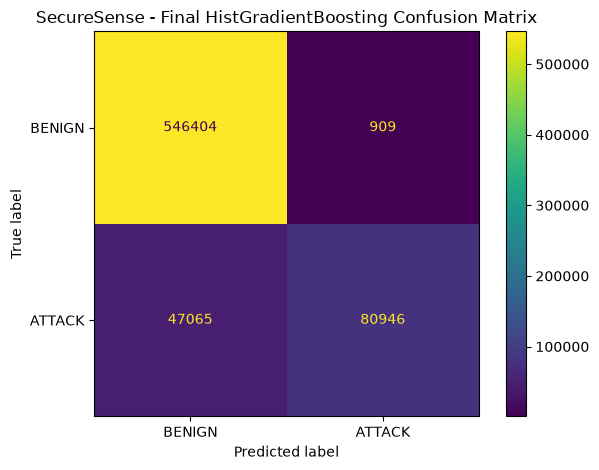

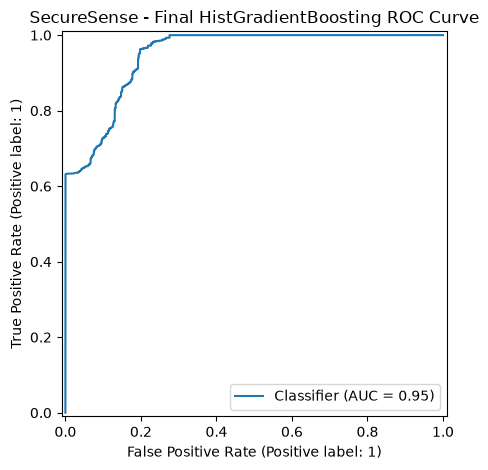

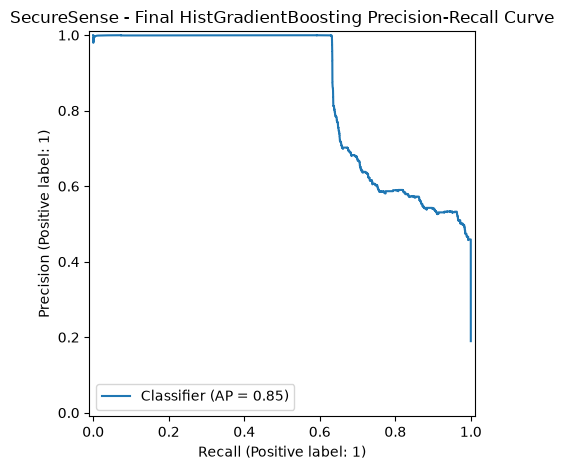


FINAL HISTOGRAM GRADIENT BOOSTING COMPLETED

Model saved   : W:\FinalYearProject\SecureSense_Project\models\final_hist_gradient_boosting.pkl
Metrics saved : W:\FinalYearProject\SecureSense_Project\results\final_hist_gradient_boosting_metrics.csv

Final Metrics:
               Model        Evaluation  Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC  Training_Time_Seconds
HistGradientBoosting Final Group-Aware  0.928962   0.988895 0.632336 0.771407 0.948125 0.850233                37.4725

✓ Evaluated on unseen source files.
✓ No source-file leakage.


In [2]:
# ============================================================
# SECURESENSE - FINAL GROUP-AWARE HISTOGRAM GRADIENT BOOSTING
# ============================================================

import os
import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# ============================================================
# 1. EXACT FINAL GROUP-AWARE SPLIT PATHS
# ============================================================

TRAIN_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\train.parquet"

TEST_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\test.parquet"

MODEL_DIR = r"W:\FinalYearProject\SecureSense_Project\models"

RESULT_DIR = r"W:\FinalYearProject\SecureSense_Project\results"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("=" * 80)
print("SECURESENSE - FINAL GROUP-AWARE HISTOGRAM GRADIENT BOOSTING")
print("=" * 80)

# ============================================================
# 2. CHECK FILES
# ============================================================

if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError(
        f"Training file not found:\n{TRAIN_PATH}"
    )

if not os.path.exists(TEST_PATH):
    raise FileNotFoundError(
        f"Testing file not found:\n{TEST_PATH}"
    )

print("\n✓ Training file found")
print("✓ Testing file found")

# ============================================================
# 3. LOAD DATA
# ============================================================

print("\nLoading training data...")
train_df = pd.read_parquet(TRAIN_PATH)

print("Loading testing data...")
test_df = pd.read_parquet(TEST_PATH)

print(f"\nTraining shape: {train_df.shape}")
print(f"Testing shape : {test_df.shape}")

# ============================================================
# 4. FEATURES AND TARGET
# ============================================================

TARGET = "BinaryLabel"

X_train = train_df.drop(
    columns=["BinaryLabel", "Label", "_source_file"],
    errors="ignore"
)

X_test = test_df.drop(
    columns=["BinaryLabel", "Label", "_source_file"],
    errors="ignore"
)

y_train = train_df[TARGET].map({
    "BENIGN": 0,
    "ATTACK": 1
})

y_test = test_df[TARGET].map({
    "BENIGN": 0,
    "ATTACK": 1
})

print(f"\nNumber of features: {X_train.shape[1]}")

# ============================================================
# 5. SOURCE-FILE LEAKAGE CHECK
# ============================================================

train_sources = set(
    train_df["_source_file"].unique()
)

test_sources = set(
    test_df["_source_file"].unique()
)

overlap = train_sources.intersection(test_sources)

print("\nSource-file overlap:", len(overlap))

if overlap:
    raise ValueError(
        f"Source-file leakage detected: {overlap}"
    )

print("✓ No source-file overlap")

# ============================================================
# 6. TRAIN HISTOGRAM GRADIENT BOOSTING
# ============================================================

print("\n" + "=" * 80)
print("TRAINING HISTOGRAM GRADIENT BOOSTING")
print("=" * 80)

model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.10,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42
)

start_time = time.time()

model.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

print(
    f"\nTraining completed in "
    f"{training_time:.2f} seconds"
)

# ============================================================
# 7. PREDICTIONS
# ============================================================

print("\nGenerating predictions...")

y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

# ============================================================
# 8. METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

pr_auc = average_precision_score(
    y_test,
    y_prob
)

print("\n" + "=" * 80)
print("FINAL HISTOGRAM GRADIENT BOOSTING RESULTS")
print("=" * 80)

print(
    f"\nAccuracy  : {accuracy:.6f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"Precision : {precision:.6f} "
    f"({precision * 100:.2f}%)"
)

print(
    f"Recall    : {recall:.6f} "
    f"({recall * 100:.2f}%)"
)

print(
    f"F1 Score  : {f1:.6f} "
    f"({f1 * 100:.2f}%)"
)

print(
    f"ROC-AUC   : {roc_auc:.6f} "
    f"({roc_auc * 100:.2f}%)"
)

print(
    f"PR-AUC    : {pr_auc:.6f} "
    f"({pr_auc * 100:.2f}%)"
)

print(
    f"Train Time: {training_time:.2f} seconds"
)

# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "BENIGN",
            "ATTACK"
        ],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\n" + "=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "BENIGN",
        "ATTACK"
    ]
).plot()

plt.title(
    "SecureSense - Final HistGradientBoosting Confusion Matrix"
)

plt.tight_layout()
plt.show()

# ============================================================
# 11. ROC CURVE
# ============================================================

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(
    "SecureSense - Final HistGradientBoosting ROC Curve"
)

plt.tight_layout()
plt.show()

# ============================================================
# 12. PRECISION-RECALL CURVE
# ============================================================

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(
    "SecureSense - Final HistGradientBoosting "
    "Precision-Recall Curve"
)

plt.tight_layout()
plt.show()

# ============================================================
# 13. SAVE MODEL
# ============================================================

model_path = os.path.join(
    MODEL_DIR,
    "final_hist_gradient_boosting.pkl"
)

joblib.dump(
    model,
    model_path
)

# ============================================================
# 14. SAVE METRICS
# ============================================================

metrics = pd.DataFrame([{
    "Model": "HistGradientBoosting",
    "Evaluation": "Final Group-Aware",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
    "Training_Time_Seconds": training_time
}])

metrics_path = os.path.join(
    RESULT_DIR,
    "final_hist_gradient_boosting_metrics.csv"
)

metrics.to_csv(
    metrics_path,
    index=False
)

# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FINAL HISTOGRAM GRADIENT BOOSTING COMPLETED")
print("=" * 80)

print(
    f"\nModel saved   : {model_path}"
)

print(
    f"Metrics saved : {metrics_path}"
)

print("\nFinal Metrics:")
print(
    metrics.to_string(index=False)
)

print("\n✓ Evaluated on unseen source files.")
print("✓ No source-file leakage.")